# Практична робота 4.13 — Частина 2
## Reinforcement Learning: DQN-агент для маршруту БПЛА в зоні дії ППО

**Групове завдання (Група 2 за планом заняття):** створити RL-агента для оптимізації маршрутів БПЛА у бойових умовах.

**Кроки:**
1. Визначення середовища симуляції (власне середовище з API як у Gymnasium: `reset()` / `step()`).
2. Розробка та навчання RL-агента (**DQN** з experience replay і target network).
3. Тестування агента в різних сценаріях.
4. Аналіз продуктивності та порівняння з базовими стратегіями.

## 0. Імпорт бібліотек та налаштування

In [1]:
import os, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import deque
import tensorflow as tf
from uav_env import UAVEnv, random_policy, greedy_policy, cautious_greedy_policy, MOVES

tf.get_logger().setLevel("ERROR")
sns.set_theme(style="whitegrid", palette="muted")
SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Середовище симуляції

**Сценарій:** БПЛА стартує з бази на лівому краю поля 10×10 і має долетіти до цілі на правому краю. На полі 4 зони ППО (квадрати 3×3); кожен крок у зоні ППО — ризик 35% бути збитим. Заряд батареї — 40 кроків. **Розташування цілі та зон ППО нове в кожному епізоді** — агент не може завчити одну карту.

| Елемент | Опис |
|---|---|
| Спостереження (14) | вектор до цілі (dx, dy), 8 сенсорів ППО в сусідніх клітинках, межі поля, заряд, «зараз у зоні ППО» |
| Дії (4) | вгору, вниз, вліво, вправо |
| Нагорода | +10 ціль; −10 збито; −5 розряд; −0.1 за крок; −0.5 за спробу вилетіти за межі; shaping +0.3 × (зменшення відстані до цілі) |

Shaping є **potential-based** (Ng et al., 1999): він прискорює навчання за рідкісної нагороди і не змінює оптимальну політику. Без нього випадкова розвідка майже ніколи не доходить до цілі (0.3% епізодів), і агент не отримує корисного сигналу.

Спостереження: [ 1.   -0.89  0.    0.    0.    0.    0.    0.    0.    0.   -1.    0.
  1.    0.  ]


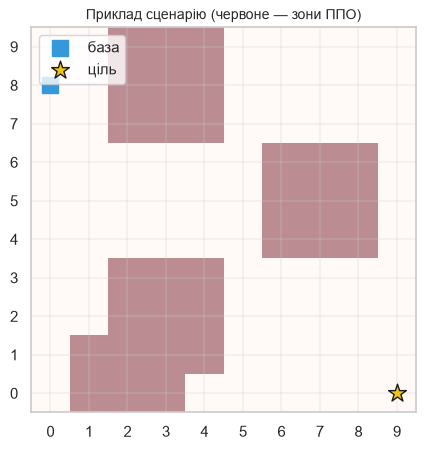

In [2]:
def draw_episode(env, ax, title=""):
    n = env.size
    ax.imshow(env.threat.T, cmap="Reds", alpha=0.45, origin="lower", extent=(-0.5, n - 0.5, -0.5, n - 0.5))
    path = np.array(env.path)
    ax.plot(path[:, 0], path[:, 1], "-o", color="#2c3e50", ms=3, lw=1.5)
    ax.scatter(*path[0], s=120, marker="s", color="#3498db", label="база", zorder=3)
    ax.scatter(*env.target, s=180, marker="*", color="#f1c40f", edgecolor="k", label="ціль", zorder=3)
    ax.set_xlim(-0.5, n - 0.5); ax.set_ylim(-0.5, n - 0.5)
    ax.set_xticks(range(n)); ax.set_yticks(range(n)); ax.grid(True, lw=0.3)
    ax.set_title(title, fontsize=10)

env = UAVEnv(seed=SEED)
obs, _ = env.reset(seed=3)
print("Спостереження:", obs.round(2))
fig, ax = plt.subplots(figsize=(5, 5))
draw_episode(env, ax, "Приклад сценарію (червоне — зони ППО)"); ax.legend(loc="upper left")
plt.show()

## 2. Базові стратегії (для порівняння)

- **Випадкова** — нижня межа.
- **Жадібна (прямий маршрут)** — найкоротший шлях до цілі без урахування ППО.
- **Обережна жадібна** — евристика оператора: рух до цілі, але не заходити в клітинку, де сенсор бачить ППО.

In [3]:
def evaluate(policy, n=500, seed0=10_000, env_kwargs=None):
    env = UAVEnv(**(env_kwargs or {}))
    rng = np.random.default_rng(0)
    events = {"reached": 0, "shot_down": 0, "battery": 0}
    rewards, steps = [], []
    for i in range(n):
        obs, _ = env.reset(seed=seed0 + i)     # однакові сценарії для всіх стратегій
        total = 0.0
        while True:
            obs, r, term, trunc, info = env.step(policy(env, obs, rng))
            total += r
            if term or trunc:
                events[info["event"]] += 1
                break
        rewards.append(total); steps.append(env.steps)
    reached_steps = [s for s, r in zip(steps, rewards) if r > 0]
    return {"Ціль досягнута": events["reached"] / n, "Збито ППО": events["shot_down"] / n,
            "Розряд батареї": events["battery"] / n, "Середня нагорода": np.mean(rewards),
            "Середня к-сть кроків": np.mean(steps)}

baselines = {"Випадкова": random_policy, "Жадібна (прямий маршрут)": greedy_policy,
             "Обережна жадібна": cautious_greedy_policy}
base_res = pd.DataFrame({name: evaluate(p) for name, p in baselines.items()}).T
base_res.round(3)

,Ціль досягнута,Збито ППО,Розряд батареї,Середня нагорода,Середня к-сть кроків
Випадкова,0.004,0.748,0.248,-11.890,21.890
Жадібна (прямий маршрут),0.318,0.682,0.000,-2.274,6.828
Обережна жадібна,0.590,0.000,0.410,4.168,24.050


## 3. DQN-агент

- **Q-мережа:** MLP 14 → 64 → 64 → 4 (оцінка Q(s, a) для кожної дії).
- **Experience replay:** буфер 30 000 переходів; навчання на випадкових міні-батчах по 64 — розриває кореляцію між послідовними кроками.
- **Target network:** копія Q-мережі, оновлюється кожні 500 кроків — стабілізує цільові значення.
- **Double DQN:** дію для цільового значення обирає онлайн-мережа, а оцінює target-мережа — це зменшує систематичну переоцінку Q-значень.
- **Вибір чекпоінта:** кожні 250 епізодів агент перевіряється на 200 *validation*-сценаріях (seed 5000+, не перетинаються ні з навчальними, ні з тестовими); зберігаються ваги з найкращою середньою нагородою. Навчання DQN нестабільне, і останні ваги не обов'язково найкращі.
- **Політика:** ε-greedy, ε спадає від 1.0 до 0.05.
- **Loss:** Huber, γ = 0.97, Adam (lr = 1e-3).

In [4]:
class DQNAgent:
    def __init__(self, obs_dim, n_actions, lr=1e-3, gamma=0.97, buffer=30_000, batch=64,
                 target_every=500, seed=SEED):
        self.n_actions, self.gamma, self.batch, self.target_every = n_actions, gamma, batch, target_every
        self.q, self.q_target = self._net(obs_dim, n_actions), self._net(obs_dim, n_actions)
        self.q_target.set_weights(self.q.get_weights())
        self.opt = tf.keras.optimizers.Adam(lr)
        self.memory = deque(maxlen=buffer)
        self.rng = np.random.default_rng(seed)
        self.steps = 0

    @staticmethod
    def _net(obs_dim, n_actions):
        return tf.keras.Sequential([tf.keras.Input((obs_dim,)),
                                    tf.keras.layers.Dense(64, activation="relu"),
                                    tf.keras.layers.Dense(64, activation="relu"),
                                    tf.keras.layers.Dense(n_actions)])

    @tf.function
    def _q_values(self, s):
        return self.q(s)

    def act(self, obs, eps=0.0):
        if self.rng.random() < eps:
            return int(self.rng.integers(self.n_actions))
        return int(tf.argmax(self._q_values(obs[None])[0]))

    @tf.function
    def _train_step(self, s, a, r, s2, done):
        a_star = tf.argmax(self.q(s2), axis=1)                                   # Double DQN
        q_next = tf.reduce_sum(self.q_target(s2) * tf.one_hot(a_star, self.n_actions), axis=1)
        target = r + self.gamma * (1.0 - done) * q_next
        with tf.GradientTape() as tape:
            q_sa = tf.reduce_sum(self.q(s) * tf.one_hot(a, self.n_actions), axis=1)
            loss = tf.reduce_mean(tf.keras.losses.huber(target[:, None], q_sa[:, None]))
        grads = tape.gradient(loss, self.q.trainable_variables)
        self.opt.apply_gradients(zip(grads, self.q.trainable_variables))
        return loss

    def remember(self, *transition):
        self.memory.append(transition)

    def replay(self):
        self.steps += 1
        if self.steps % self.target_every == 0:
            self.q_target.set_weights(self.q.get_weights())
        if len(self.memory) < 500 or self.steps % 2:
            return None
        idx = self.rng.integers(len(self.memory), size=self.batch)
        s, a, r, s2, d = zip(*[self.memory[i] for i in idx])
        return float(self._train_step(np.array(s, np.float32), np.array(a, np.int32),
                                      np.array(r, np.float32), np.array(s2, np.float32),
                                      np.array(d, np.float32)))

## 4. Навчання

In [5]:
EPISODES = 3000
EVAL_EVERY = 250
agent = DQNAgent(obs_dim=14, n_actions=4)
env = UAVEnv(seed=7)       # навчальні сценарії — інші seed, ніж validation (5000+) і test (10 000+)
dqn_policy = lambda env, obs, rng: agent.act(obs, eps=0.0)
eps, log, val_log = 1.0, [], []
best_val, best_weights = -np.inf, None
t0 = time.time()
for ep in range(EPISODES):
    obs, _ = env.reset()
    total, losses = 0.0, []
    while True:
        a = agent.act(obs, eps)
        obs2, r, term, trunc, info = env.step(a)
        agent.remember(obs, a, r, obs2, float(term))   # truncation (розряд) — не термінальний стан для bootstrap
        l = agent.replay()
        if l is not None:
            losses.append(l)
        obs, total = obs2, total + r
        if term or trunc:
            break
    eps = max(0.05, eps * 0.997)
    log.append({"episode": ep + 1, "reward": total, "event": info["event"], "eps": eps,
                "loss": np.mean(losses) if losses else np.nan})
    if (ep + 1) % EVAL_EVERY == 0:
        v = evaluate(dqn_policy, n=200, seed0=5000)
        val_log.append({"episode": ep + 1, **v})
        mark = ""
        if v["Середня нагорода"] > best_val:
            best_val, best_weights, mark = v["Середня нагорода"], agent.q.get_weights(), "  ← найкращий"
        print(f"епізод {ep+1:5d} | ε={eps:.2f} | validation: нагорода {v['Середня нагорода']:5.2f}, "
              f"ціль {v['Ціль досягнута']:.0%}, збито {v['Збито ППО']:.0%} | {time.time() - t0:.0f} с{mark}")
log, val_log = pd.DataFrame(log), pd.DataFrame(val_log)
agent.q.set_weights(best_weights)
best_ep = int(val_log.loc[val_log["Середня нагорода"].idxmax(), "episode"])
print(f"\nОбрано чекпоінт епізоду {best_ep} (validation нагорода {best_val:.2f})")

епізод   250 | ε=0.47 | validation: нагорода  1.00, ціль 48%, збито 26% | 56 с  ← найкращий


епізод   500 | ε=0.22 | validation: нагорода  5.69, ціль 68%, збито 6% | 82 с  ← найкращий


епізод   750 | ε=0.11 | validation: нагорода  3.91, ціль 62%, збито 2% | 101 с


епізод  1000 | ε=0.05 | validation: нагорода  6.74, ціль 74%, збито 2% | 117 с  ← найкращий


епізод  1250 | ε=0.05 | validation: нагорода  6.34, ціль 74%, збито 16% | 139 с


...

епізод  2000 | ε=0.05 | validation: нагорода  7.44, ціль 80%, збито 18% | 185 с  ← найкращий


епізод  2250 | ε=0.05 | validation: нагорода  7.49, ціль 79%, збито 12% | 200 с  ← найкращий


епізод  2500 | ε=0.05 | validation: нагорода  8.21, ціль 83%, збито 16% | 215 с  ← найкращий


епізод  2750 | ε=0.05 | validation: нагорода  8.45, ціль 84%, збито 16% | 229 с  ← найкращий


епізод  3000 | ε=0.05 | validation: нагорода  8.23, ціль 83%, збито 17% | 242 с

Обрано чекпоінт епізоду 2750 (validation нагорода 8.45)


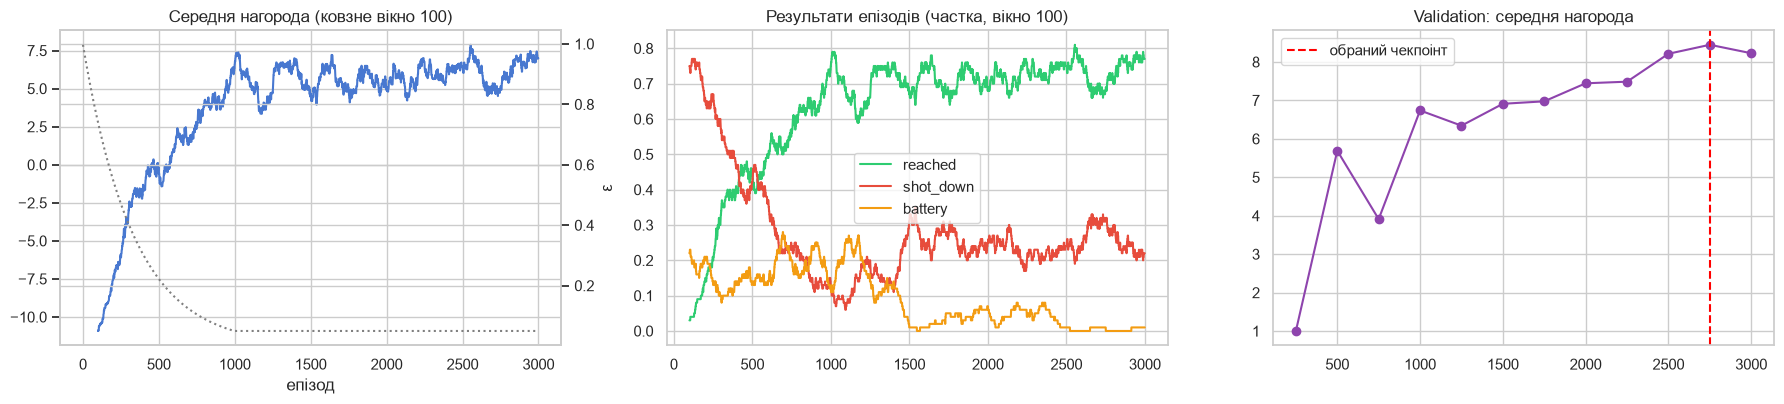

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
axes[0].plot(log.reward.rolling(100).mean())
axes[0].set_title("Середня нагорода (ковзне вікно 100)"); axes[0].set_xlabel("епізод")
for ev, c in [("reached", "#2ecc71"), ("shot_down", "#e74c3c"), ("battery", "#f39c12")]:
    axes[1].plot((log.event == ev).rolling(100).mean(), label=ev, color=c)
axes[1].set_title("Результати епізодів (частка, вікно 100)"); axes[1].legend()
axes[2].plot(val_log.episode, val_log["Середня нагорода"], "o-", color="#8e44ad")
axes[2].axvline(best_ep, color="red", ls="--", label="обраний чекпоінт")
axes[2].set_title("Validation: середня нагорода"); axes[2].legend()
ax2 = axes[0].twinx(); ax2.plot(log.eps, color="gray", ls=":", label="ε"); ax2.set_ylabel("ε")
plt.tight_layout(); plt.show()

## 5. Тестування: порівняння з базовими стратегіями

500 **нових** сценаріїв (seed 10 000+, не траплялись під час навчання), однакові для всіх стратегій. Агент діє жадібно (ε = 0).

In [7]:
results = pd.concat([base_res, pd.DataFrame({"DQN-агент": evaluate(dqn_policy)}).T])
results.round(3)

,Ціль досягнута,Збито ППО,Розряд батареї,Середня нагорода,Середня к-сть кроків
Випадкова,0.004,0.748,0.248,-11.890,21.890
Жадібна (прямий маршрут),0.318,0.682,0.000,-2.274,6.828
Обережна жадібна,0.590,0.000,0.410,4.168,24.050
DQN-агент,0.772,0.228,0.000,7.082,15.198


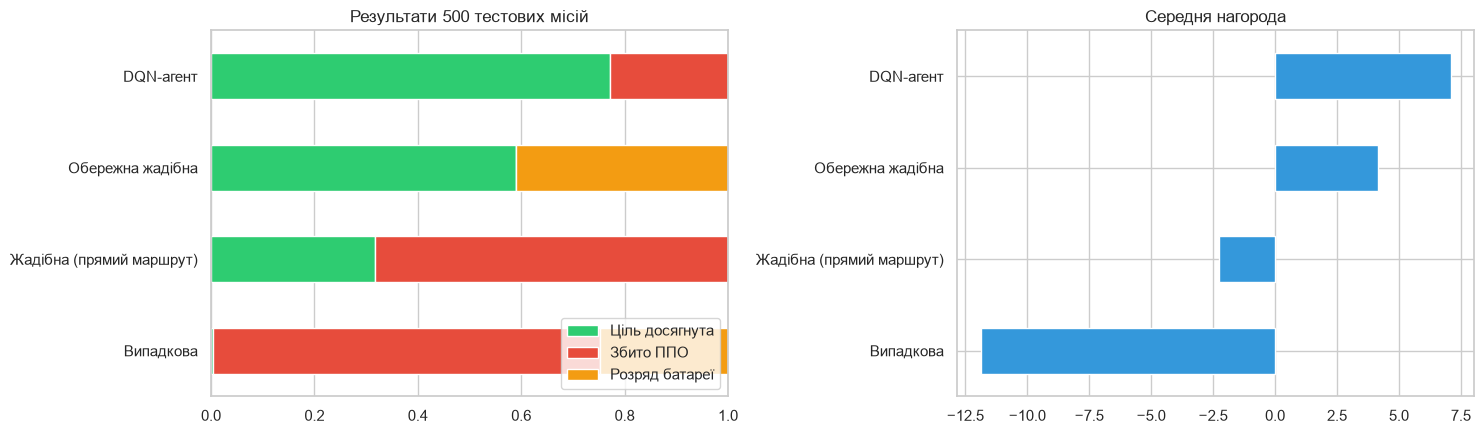

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
results[["Ціль досягнута", "Збито ППО", "Розряд батареї"]].plot.barh(
    stacked=True, ax=axes[0], color=["#2ecc71", "#e74c3c", "#f39c12"])
axes[0].set_title("Результати 500 тестових місій"); axes[0].set_xlim(0, 1); axes[0].legend(loc="lower right")
results["Середня нагорода"].plot.barh(ax=axes[1], color="#3498db")
axes[1].set_title("Середня нагорода")
plt.tight_layout(); plt.show()

### 5.1 Приклади маршрутів на однакових тестових сценаріях

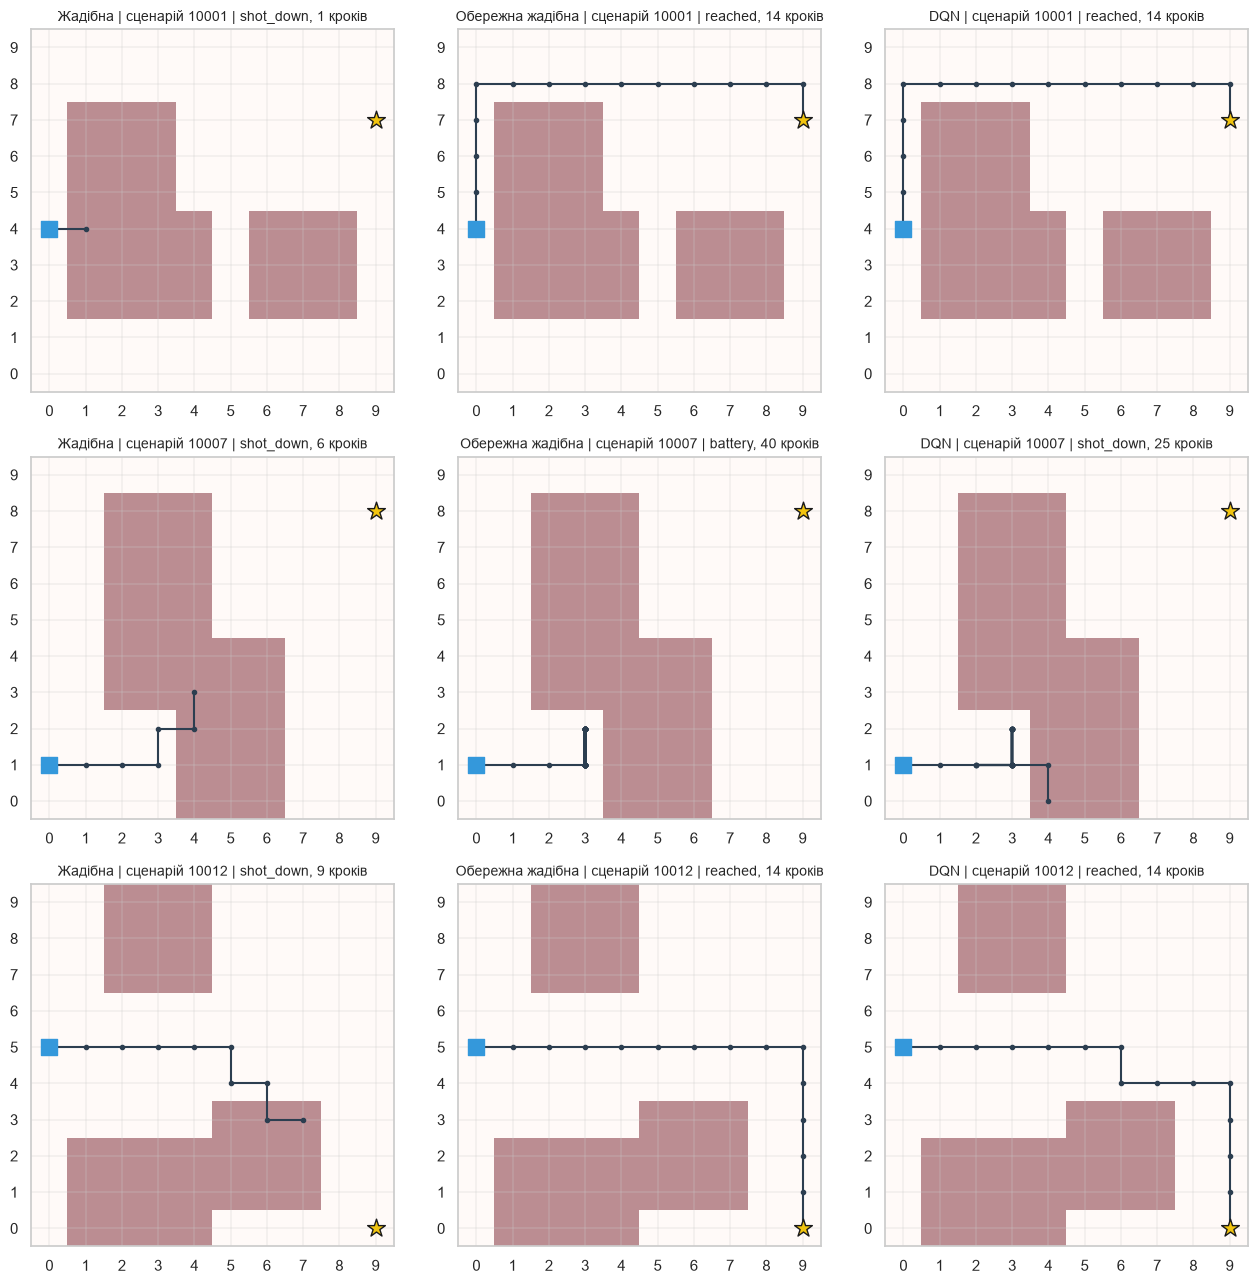

In [9]:
def run_episode(policy, seed):
    env = UAVEnv()
    obs, _ = env.reset(seed=seed)
    rng = np.random.default_rng(0)
    while True:
        obs, r, term, trunc, info = env.step(policy(env, obs, rng))
        if term or trunc:
            return env, info["event"]

policies = {"Жадібна": greedy_policy, "Обережна жадібна": cautious_greedy_policy, "DQN": dqn_policy}
seeds = [10_001, 10_007, 10_012]
fig, axes = plt.subplots(len(seeds), 3, figsize=(13, 13))
for row, sd in enumerate(seeds):
    for col, (name, p) in enumerate(policies.items()):
        e, ev = run_episode(p, sd)
        draw_episode(e, axes[row, col], f"{name} | сценарій {sd} | {ev}, {e.steps} кроків")
plt.tight_layout(); plt.show()

## 6. Тестування в інших сценаріях (стійкість)

Перевіряємо, як агент, навчений на 4 зонах ППО, поводиться в умовах, яких не бачив під час навчання:
- **щільніша ППО** — 6 зон;
- **розріджена ППО** — 2 зони;
- **вища небезпека** — ймовірність ураження 0.6 за крок.

In [10]:
scenarios = {"Навчальні умови (4 зони, p=0.35)": {},
             "Щільна ППО (6 зон)": {"n_threats": 6},
             "Розріджена ППО (2 зони)": {"n_threats": 2},
             "Висока небезпека (p=0.6)": {"p_hit": 0.6}}
rows = []
for sc_name, kw in scenarios.items():
    for name, p in [("Обережна жадібна", cautious_greedy_policy), ("DQN", dqn_policy)]:
        r = evaluate(p, n=300, env_kwargs=kw)
        rows.append({"Сценарій": sc_name, "Стратегія": name, **r})
robust = pd.DataFrame(rows)
robust.pivot(index="Сценарій", columns="Стратегія", values="Ціль досягнута").round(3)

Стратегія,DQN,Обережна жадібна
Сценарій,,
Висока небезпека (p=0.6),0.750,0.593
"Навчальні умови (4 зони, p=0.35)",0.777,0.593
Розріджена ППО (2 зони),0.957,0.857
Щільна ППО (6 зон),0.583,0.390


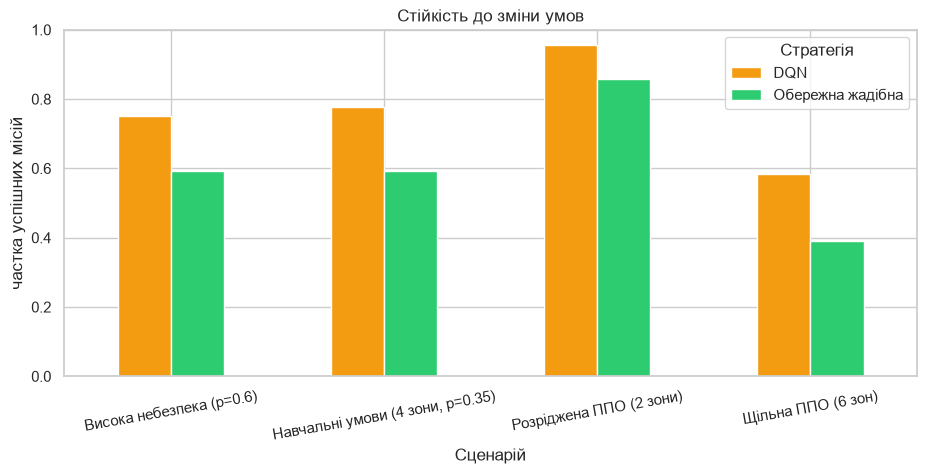

In [11]:
robust.pivot(index="Сценарій", columns="Стратегія", values="Ціль досягнута").plot.bar(
    rot=10, figsize=(11, 4.5), color=["#f39c12", "#2ecc71"])
plt.ylabel("частка успішних місій"); plt.ylim(0, 1); plt.title("Стійкість до зміни умов")
plt.show()

### 6.1 Збереження моделі

In [12]:
os.makedirs("models", exist_ok=True)
agent.q.save("models/dqn_uav.keras")
print("Збережено: models/dqn_uav.keras", f"({os.path.getsize('models/dqn_uav.keras') / 1024:.0f} КБ)")

Збережено: models/dqn_uav.keras (39 КБ)


## 7. Висновки

1. **Середовище.** Власна симуляція з новою картою ППО в кожному епізоді змушує агента вчити *політику* за сенсорами, а не завчати маршрут.
2. **Прямий маршрут** (жадібна стратегія) найкоротший (≈7 кроків), але 68% місій закінчуються ураженням БПЛА: ППО не враховується.
3. **Обережна евристика** ніколи не заходить у зону ППО (0% збитих), але в 41% місій «застрягає» перед перешкодою і розряджає батарею. Правило не вміє планувати обхід.
4. **DQN-агент** на 500 нових тестових сценаріях досягає цілі в **77.2%** місій проти 59.0% в обережної евристики. Середня нагорода 7.08 проти 4.17, маршрут ≈15 кроків. Агент навчився компромісу: переважно оминає ППО, але іноді свідомо ризикує, щоб не розрядити батарею. Тому 22.8% місій закінчуються ураженням. Зменшити цю частку можна, підвищивши штраф за втрату БПЛА.
5. **Стійкість.** В умовах, яких агент не бачив під час навчання, він також кращий за евристику:
   - щільна ППО (6 зон): 58.3% проти 39.0%;
   - висока небезпека (p = 0.6): 75.0% проти 59.3%;
   - розріджена ППО: 95.7% проти 85.7%.
6. **Що виявилось критичним:**
   - **reward shaping** — без нього агент не навчався зовсім (рідкісна нагорода);
   - **Double DQN + вибір чекпоінта на validation** — перша версія (звичайний DQN, останні ваги) давала лише 62.6% успіху і середню нагороду 4.10, нижчу за евристику;
   - навчання DQN нестабільне: якість на validation коливалась між оцінками (див. графік).
7. **Розрив validation/test:** на validation обраний чекпоінт мав 84% успіху, на test — 77%. Частина переваги на validation є результатом вибору найкращого з 12 чекпоінтів, тому чесна оцінка — тестова.

**Обмеження та наступні кроки:**
- Модель спрощена: сітчаста 2D-карта без вітру, висоти й маневрування; ППО статична, а агент бачить лише сусідні клітинки.
- Можливий розвиток:
  - Dueling DQN / PPO;
  - сенсор більшого радіуса або пам'ять (LSTM);
  - рухомі загрози;
  - кілька БПЛА (multi-agent RL);
  - перевірка в реалістичному симуляторі (наприклад, AirSim).